# Clasificación de presencia de dron: MFCC + SVM

**Etiquetas corregidas conforme a tu indicación:** todos los segmentos completos de las ocho grabaciones en `con_dron` son positivos (1); todos los de los dos archivos en `sin_dron` son negativos (0). `154519` se incluye completo. La mayor audibilidad inicial no cambia la etiqueta.

Se intenta detectar presencia a partir del audio. Si el dron es demasiado lejano, la etiqueta física puede seguir siendo positiva aunque no exista señal acústica suficiente para distinguirlo.

## Modelo elegido
**SVM con kernel RBF y estadísticas de MFCC**, normalización aprendida solo con entrenamiento y ponderación por grupo/clase. Es una base adecuada para este pequeño número de grabaciones: no requiere entrenar una red profunda desde cero. No afirmamos que sea el mejor modelo universal ni seleccionamos el ganador mirando la evaluación. Se compara con un clasificador basado solo en volumen.

## Evaluación
- Ventanas de 2 s sin solapamiento; el último fragmento incompleto se descarta.
- Dos particiones por grabación, sin mezclar segmentos del mismo archivo entre entrenamiento y evaluación.
- **Precisión, recall, F1 y VN/FP/FN/VP**, por partición, por archivo y globalmente.
- Solo hay dos negativos y los nombres comparten fecha: resultados exploratorios; no hay prueba externa de otros días. Configura `GROUP_OVERRIDES` si conoces sesiones que deban permanecer juntas.
- No se optimizan hiperparámetros ni umbral con la evaluación. Márgenes SVM no son probabilidades.

Ejecuta todas las celdas en orden. Se guardan modelo, configuración y resultados. Los WAV originales no se modifican.


## Cómo leer los resultados

La clase positiva es **dron**. Filas = realidad indicada por el usuario; columnas = predicción.

| | Predice sin dron | Predice dron |
|---|---|---|
| Real sin dron | VN: negativo correcto | FP: falsa detección |
| Real con dron | FN: dron no detectado | VP: positivo correcto |

- **Precisión = VP / (VP + FP)**: cuántas detecciones positivas son correctas.
- **Recall = VP / (VP + FN)**: qué fracción de positivos detectamos.
- **F1 = 2·VP / (2·VP + FP + FN)**: combina precisión y recall.
- **Especificidad = VN / (VN + FP)**: qué fracción de negativos reconocemos.

Precisión, recall y F1 no incluyen VN directamente; por eso mostramos la matriz y especificidad. Cuando un denominador no permite definir una métrica, puede aparecer NaN; sklearn usa 0 para precisión/F1 sin positivos predichos según configuración. Las métricas son por ventanas, no por eventos ni por hora.


## Resultado de la ejecución verificada

828 ventanas de 2 s: 687 positivas y 141 negativas. Se incluyeron todos los archivos completos, descartando solo las colas menores de 2 s. Cada predicción de evaluación procede de un modelo que no vio esa grabación.

| Modelo | Precisión | Recall | F1 | Especificidad |
|---|---:|---:|---:|---:|
| MFCC + SVM | 85,92 % | 88,79 % | 87,33 % | 29,08 % |
| Solo RMS | 72,18 % | 38,14 % | 49,90 % | 28,37 % |

Matriz SVM: **VN=41, FP=100, FN=77, VP=610**. Las filas son realidad y las columnas predicción.

**Limitación práctica:** 100 de 141 ventanas negativas producen falsa detección (70,92 %). El F1 está favorecido por el predominio de positivos; predecir siempre dron da F1 de aproximadamente 90,69 %. El SVM tiene exactitud balanceada de 58,93 %, pero todavía no es un detector fiable. No se debe presentar este experimento como prueba de un modelo óptimo.

Se ejecutaron todas las celdas, se verificó la separación entre grupos y se revisó la matriz de confusión. Las métricas actuales se obtienen en estas grabaciones, no en sesiones externas independientes. Si cambias datos o configuración, este resumen estático deja de aplicar: utiliza las salidas recalculadas.


In [1]:
# %pip install numpy scikit-learn matplotlib ipython joblib


In [2]:
from pathlib import Path
import csv, json, wave, hashlib, platform
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score,
    recall_score, f1_score, balanced_accuracy_score, average_precision_score, roc_auc_score)
import sklearn, joblib

ROOTS={1:Path(r'C:\Users\alche\Downloads\con_dron'),0:Path(r'C:\Users\alche\Downloads\sin_dron')}
OUT=Path.cwd()/'resultados_presencia_completa'
OUT.mkdir(exist_ok=True)
USE_FOLDER_LABELS=True
CHANNEL=0  # 0 izquierdo, 1 derecho. No mezclamos los canales.
WINDOW_S=2.0
HOP_S=2.0  # Sin solapamiento para la evaluación por ventanas.
SEED=42
GROUP_OVERRIDES={}  # {'nombre.wav':'sesion_01'}; agrupa capturas de una misma sesión.
records=[]
for label,root in ROOTS.items():
    assert root.is_dir(),f'No existe {root}'
    for path in sorted(root.rglob('*')):
        if path.is_file() and path.suffix.lower()=='.wav':
            records.append(dict(path=path,folder_label=label,group=GROUP_OVERRIDES.get(path.name,str(path))))
assert records,'No hay WAV'
assert len({r['path'].name for r in records})==len(records),'Nombres repetidos: usa claves únicas para anotar.'
print('Archivos:',len(records),'| etiqueta de presencia aplicada a TODO el archivo según el usuario')


Archivos: 10 | etiqueta de presencia aplicada a TODO el archivo según el usuario


## 1. Funciones y representación
Lector PCM de 16 bits. Extractor didáctico con Hann de 32 ms, avance de 10 ms, banco HTK de 64 bandas y 20 MFCC. Se excluye C0 y se resumen media y desviación temporal de los otros coeficientes. Esto reduce dependencia del nivel global, pero no garantiza invariancia al micrófono o al ambiente. No aplica limpieza agresiva ni aumento de datos. No equivale al frontend de PANNs.


In [3]:
def read_audio(path):
    with wave.open(str(path),'rb') as f:
        sr,ch,width=f.getframerate(),f.getnchannels(),f.getsampwidth()
        assert width==2 and f.getcomptype()=='NONE',f'Formato no compatible: {path}'
        raw=f.readframes(f.getnframes())
    x=np.frombuffer(raw,dtype='<i2').reshape(-1,ch).astype(np.float64)/32768
    assert CHANNEL<ch,'Canal no disponible'
    return x,sr,hashlib.sha256(raw).hexdigest()

def window_label(record,start,end):
    return record['folder_label'],'presencia_confirmada_por_usuario'

def features(x, sr, n_mels=64, n_mfcc=20):
    frame = round(0.032 * sr)
    hop = round(0.010 * sr)
    n_fft = 2**int(np.ceil(np.log2(frame)))
    assert frame <= n_fft
    if len(x) < frame:
        x = np.pad(x, (0, frame-len(x)))
    frames = np.lib.stride_tricks.sliding_window_view(x, frame)[::hop]
    window = np.hanning(frame)
    power = np.abs(np.fft.rfft(frames*window, n=n_fft, axis=1))**2 / np.sum(window**2)
    hz_to_mel = lambda hz: 2595*np.log10(1+hz/700)
    mel_to_hz = lambda mel: 700*(10**(mel/2595)-1)
    edges = mel_to_hz(np.linspace(hz_to_mel(0), hz_to_mel(sr/2), n_mels+2))
    freqs = np.fft.rfftfreq(n_fft, 1/sr)
    filters = np.maximum(0, np.minimum(
        (freqs[None, :]-edges[:-2, None])/(edges[1:-1]-edges[:-2])[:, None],
        (edges[2:, None]-freqs[None, :])/(edges[2:]-edges[1:-1])[:, None]))
    assert np.all(filters.sum(axis=1) > 0)
    filters /= filters.sum(axis=1, keepdims=True)
    mel = filters @ power.T
    logmel = 10*np.log10(np.maximum(mel, 1e-12))
    k, j = np.arange(n_mfcc)[:, None], np.arange(n_mels)[None, :]
    dct = np.sqrt(2/n_mels)*np.cos(np.pi/n_mels*(j+0.5)*k)
    dct[0] /= np.sqrt(2)
    mfcc = dct @ logmel
    # PCEN educativo: media exponencial causal, constante de tiempo 0.4 s.
    smooth = np.empty_like(mel)
    smooth[:, 0] = mel[:, 0]
    coefficient = 1-np.exp(-(hop/sr)/0.4)
    for t in range(1, mel.shape[1]):
        smooth[:, t] = (1-coefficient)*smooth[:, t-1] + coefficient*mel[:, t]
    pcen = (mel/(1e-6+smooth)**0.98 + 2)**0.5 - np.sqrt(2)
    times = (np.arange(mel.shape[1])*hop+frame/2)/sr
    return dict(logmel=logmel, mfcc=mfcc, pcen=pcen, times=times)

def vector(clip,sr):
    mfcc=features(clip,sr)['mfcc'][1:]
    return np.concatenate([mfcc.mean(axis=1),mfcc.std(axis=1)])


## 2. Extraer ventanas y auditar etiquetas
Se procesa un archivo a la vez. Si aparecen duplicados PCM, el proceso se detiene para revisarlos y evitar contaminación. No se remuestrea: se exige la misma frecuencia en todos los archivos. La cola menor de 2 s se descarta. El tiempo de audio etiquetado no se multiplica artificialmente mediante solapamiento.

In [ ]:
rows=[]; vectors=[]; audit=[]; seen={}; rates=set(); excluded=0
for rec in records:
    x,sr,digest=read_audio(rec['path']);rates.add(sr)
    duration=len(x)/sr
    if digest in seen:
        raise ValueError('Audio duplicado: elimina el duplicado o revisa su procedencia antes de evaluar.')
    seen[digest]=rec['path'].name
    y=x[:,CHANNEL];size=round(WINDOW_S*sr);step=round(HOP_S*sr)
    audit.append(dict(file=rec['path'].name,seconds=duration,sr=sr,channels=x.shape[1],
        rms_dbfs=float(20*np.log10(max(np.sqrt(np.mean(y*y)),1e-12))),
        saturation_pct=float(100*np.mean((y<=-1)|(y>=32767/32768))),sha256=digest))
    for start in range(0,len(y)-size+1,step):
        a,b=start/sr,(start+size)/sr
        label,source=window_label(rec,a,b)
        if label is None: excluded+=1;continue
        clip=y[start:start+size]
        vectors.append(vector(clip,sr))
        rows.append(dict(file=rec['path'].name,path=str(rec['path']),group=rec['group'],
            start_s=a,end_s=b,label=label,label_source=source,
            rms_dbfs=float(20*np.log10(max(np.sqrt(np.mean(clip*clip)),1e-12)))))
    print(rec['path'].name, '|',round(duration,1),'s | saturación:',round(audit[-1]['saturation_pct'],3),'%')
assert len(rates)==1,'Frecuencias distintas: definir y validar remuestreo antes de continuar.'
assert vectors,'No quedan ventanas etiquetadas'
X=np.stack(vectors);y=np.array([r['label'] for r in rows]);groups=np.array([r['group'] for r in rows])
energy=np.array([[r['rms_dbfs']] for r in rows])
assert np.isfinite(X).all()
print('Matriz:',X.shape,'| excluidas:',excluded)
print('Etiquetas:',{str(k):int(np.sum(y==k)) for k in np.unique(y)})
print('Fuentes:',{k:sum(r['label_source']==k for r in rows) for k in set(r['label_source'] for r in rows)})


audio_20260831_154519.wav | 169.0 s | saturación: 0.47 %
audio_20260831_155323.wav | 177.2 s | saturación: 0.381 %
audio_20260831_155940.wav | 184.0 s | saturación: 0.109 %
audio_20260831_163717.wav | 193.9 s | saturación: 0.245 %
audio_20260831_164727.wav | 171.7 s | saturación: 0.074 %


## 3. Escuchar y explorar una ventana por grabación
Se muestra la primera ventana incluida de cada archivo. Cambia la selección para revisar otros momentos; escuchar una ventana no valida todas las etiquetas.

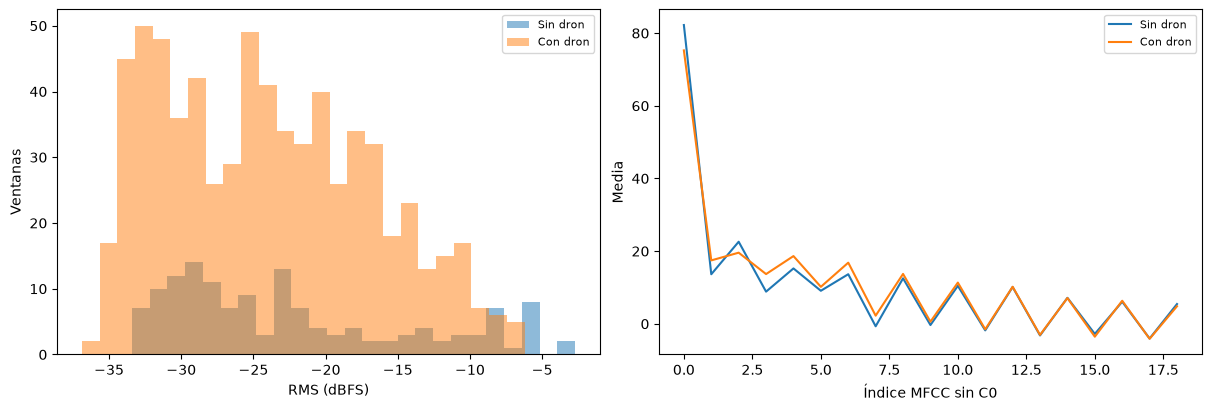

audio_20260831_154519.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_155323.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_155940.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_163717.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_164727.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_165207.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_170058.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_172820.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_124300.wav 0.0 2.0 presencia_confirmada_por_usuario


audio_20260831_145202.wav 0.0 2.0 presencia_confirmada_por_usuario


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for lab,title in [(0,'Sin dron'),(1,'Con dron')]:
    axes[0].hist(energy[y==lab,0],bins=25,alpha=.5,label=title)
    axes[1].plot(X[y==lab,:19].mean(axis=0),label=title)
axes[0].set(xlabel='RMS (dBFS)',ylabel='Ventanas');axes[1].set(xlabel='Índice MFCC sin C0',ylabel='Media')
for ax in axes:ax.legend(fontsize=8)
plt.show()
for rec in records:
    candidates=[r for r in rows if r['file']==rec['path'].name]
    if not candidates:continue
    r=candidates[0];x,sr,_=read_audio(rec['path'])
    print(r['file'],r['start_s'],r['end_s'],r['label_source'])
    display(Audio(x[round(r['start_s']*sr):round(r['end_s']*sr),CHANNEL],rate=sr,normalize=False))


## 4. Validación por grabación (dos particiones)
Estandarización ajustada solo con entrenamiento mediante Pipeline. Hiperparámetros fijados antes de evaluar: SVM RBF, C=1, gamma=scale. Se ponderan las ventanas para que cada combinación grupo/clase tenga el mismo peso y las dos clases tengan peso total igual. La referencia RMS usa regresión logística.

Cada grupo debe aparecer únicamente en entrenamiento o evaluación en cada partición. Ambos deben contener las dos clases. Si una partición no tiene ambas clases, la evaluación se detiene. No se relajan las restricciones para producir una cifra.


In [ ]:
for label in [0,1]:
    assert len(set(groups[y==label]))>=2, f'Faltan al menos dos grupos con clase {label}; recopila más grabaciones independientes.'
cv=StratifiedGroupKFold(n_splits=2,shuffle=True,random_state=SEED)
splits=list(cv.split(X,y,groups))
for train,test in splits:
    assert not set(groups[train]) & set(groups[test])
    assert len(np.unique(y[train]))==2 and len(np.unique(y[test]))==2, 'Partición sin ambas clases: revisar grupos.'

def weights(labels,group_ids):
    w=np.zeros(len(labels),float)
    for label in [0,1]:
        unique=np.unique(group_ids[labels==label])
        for group in unique:
            mask=(labels==label)&(group_ids==group)
            w[mask]=1/(len(unique)*mask.sum())
    return w*len(w)/w.sum()

def metrics(labels,pred,scores):
    tn,fp,fn,tp=confusion_matrix(labels,pred,labels=[0,1]).ravel()
    sensitivity=tp/(tp+fn) if tp+fn else float('nan')
    specificity=tn/(tn+fp) if tn+fp else float('nan')
    return dict(n=len(labels),VN=int(tn),FP=int(fp),FN=int(fn),VP=int(tp),recall=sensitivity,
        precision=precision_score(labels,pred,zero_division=0),f1=f1_score(labels,pred,zero_division=0),
        balanced_accuracy=(sensitivity+specificity)/2 if len(set(labels))==2 else float('nan'),
        specificity=tn/(tn+fp) if tn+fp else float('nan'),
        average_precision=average_precision_score(labels,scores) if len(set(labels))==2 else float('nan'),
        roc_auc=roc_auc_score(labels,scores) if len(set(labels))==2 else float('nan'))

oof={}; fold_results=[]; fold_id=np.full(len(y),-1)
for name,data in [('MFCC_SVM',X),('RMS_logistica',energy)]:
    scores=np.full(len(y),np.nan);pred=np.full(len(y),-1)
    for fold,(train,test) in enumerate(splits):
        estimator=SVC(C=1.,gamma='scale',kernel='rbf') if name=='MFCC_SVM' else LogisticRegression(C=1.,max_iter=2000,random_state=SEED)
        model=make_pipeline(StandardScaler(),estimator)
        parameter='svc__sample_weight' if name=='MFCC_SVM' else 'logisticregression__sample_weight'
        model.fit(data[train],y[train],**{parameter:weights(y[train],groups[train])})
        scores[test]=model.decision_function(data[test]);pred[test]=(scores[test]>=0).astype(int)
        fold_id[test]=fold
        result=dict(model=name,fold=fold,**metrics(y[test],pred[test],scores[test]));fold_results.append(result)
        print(name,'partición',fold,'| grupos evaluación:',len(set(groups[test])), '|',result)
    assert np.isfinite(scores).all()
    oof[name]=dict(scores=scores,pred=pred)
print('RESUMEN DESCRIPTIVO FUERA DE ENTRENAMIENTO')
for name,result in oof.items():print(name,metrics(y,result['pred'],result['scores']))
print('AP/AUC agrupadas combinan márgenes de modelos distintos; prioriza las métricas por partición.')


MFCC_SVM partición 0 | grupos evaluación: 5 | {'model': 'MFCC_SVM', 'fold': 0, 'n': 422, 'VN': 16, 'FP': 53, 'FN': 40, 'VP': 313, 'recall': np.float64(0.886685552407932), 'precision': 0.855191256830601, 'f1': 0.8706536856745479, 'balanced_accuracy': np.float64(0.5592848051894732), 'specificity': np.float64(0.2318840579710145), 'average_precision': 0.9019165730765333, 'roc_auc': 0.6627663505357803}
MFCC_SVM partición 1 | grupos evaluación: 5 | {'model': 'MFCC_SVM', 'fold': 1, 'n': 406, 'VN': 25, 'FP': 47, 'FN': 37, 'VP': 297, 'recall': np.float64(0.8892215568862275), 'precision': 0.8633720930232558, 'f1': 0.8761061946902655, 'balanced_accuracy': np.float64(0.6182218895542249), 'specificity': np.float64(0.3472222222222222), 'average_precision': 0.9391585293620893, 'roc_auc': 0.7520375914836993}
RMS_logistica partición 0 | grupos evaluación: 5 | {'model': 'RMS_logistica', 'fold': 0, 'n': 422, 'VN': 14, 'FP': 55, 'FN': 198, 'VP': 155, 'recall': np.float64(0.43909348441926344), 'precision':

## 5. Errores por archivo y línea temporal
Las predicciones siguientes son fuera de entrenamiento: cada archivo fue evaluado por un modelo que no vio su grupo. El margen SVM no es una probabilidad. El umbral 0 está fijado; cambiarlo mirando estas etiquetas convertiría esta evaluación en ajuste.

Se reporta la fracción de ventanas negativas detectadas como positivas. No se denomina falsas alarmas por hora: para eso hay que definir eventos, unir detecciones contiguas y evaluar audio continuo con etiquetas temporales completas.

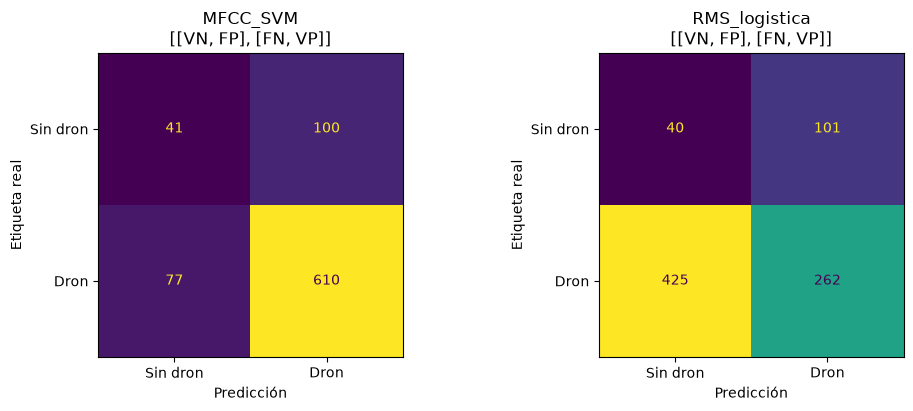

{'file': 'audio_20260831_154519.wav', 'fold': 0, 'n': 84, 'positive_prediction_fraction': 0.8333333333333334, 'label_positive_fraction': 1.0, 'VN': 0, 'FP': 0, 'FN': 14, 'VP': 70, 'recall': np.float64(0.8333333333333334), 'precision': 1.0, 'f1': 0.9090909090909091, 'balanced_accuracy': nan, 'specificity': nan, 'average_precision': nan, 'roc_auc': nan}
{'file': 'audio_20260831_155323.wav', 'fold': 0, 'n': 88, 'positive_prediction_fraction': 0.9090909090909091, 'label_positive_fraction': 1.0, 'VN': 0, 'FP': 0, 'FN': 8, 'VP': 80, 'recall': np.float64(0.9090909090909091), 'precision': 1.0, 'f1': 0.9523809523809523, 'balanced_accuracy': nan, 'specificity': nan, 'average_precision': nan, 'roc_auc': nan}
{'file': 'audio_20260831_155940.wav', 'fold': 1, 'n': 92, 'positive_prediction_fraction': 1.0, 'label_positive_fraction': 1.0, 'VN': 0, 'FP': 0, 'FN': 0, 'VP': 92, 'recall': np.float64(1.0), 'precision': 1.0, 'f1': 1.0, 'balanced_accuracy': nan, 'specificity': nan, 'average_precision': nan, '

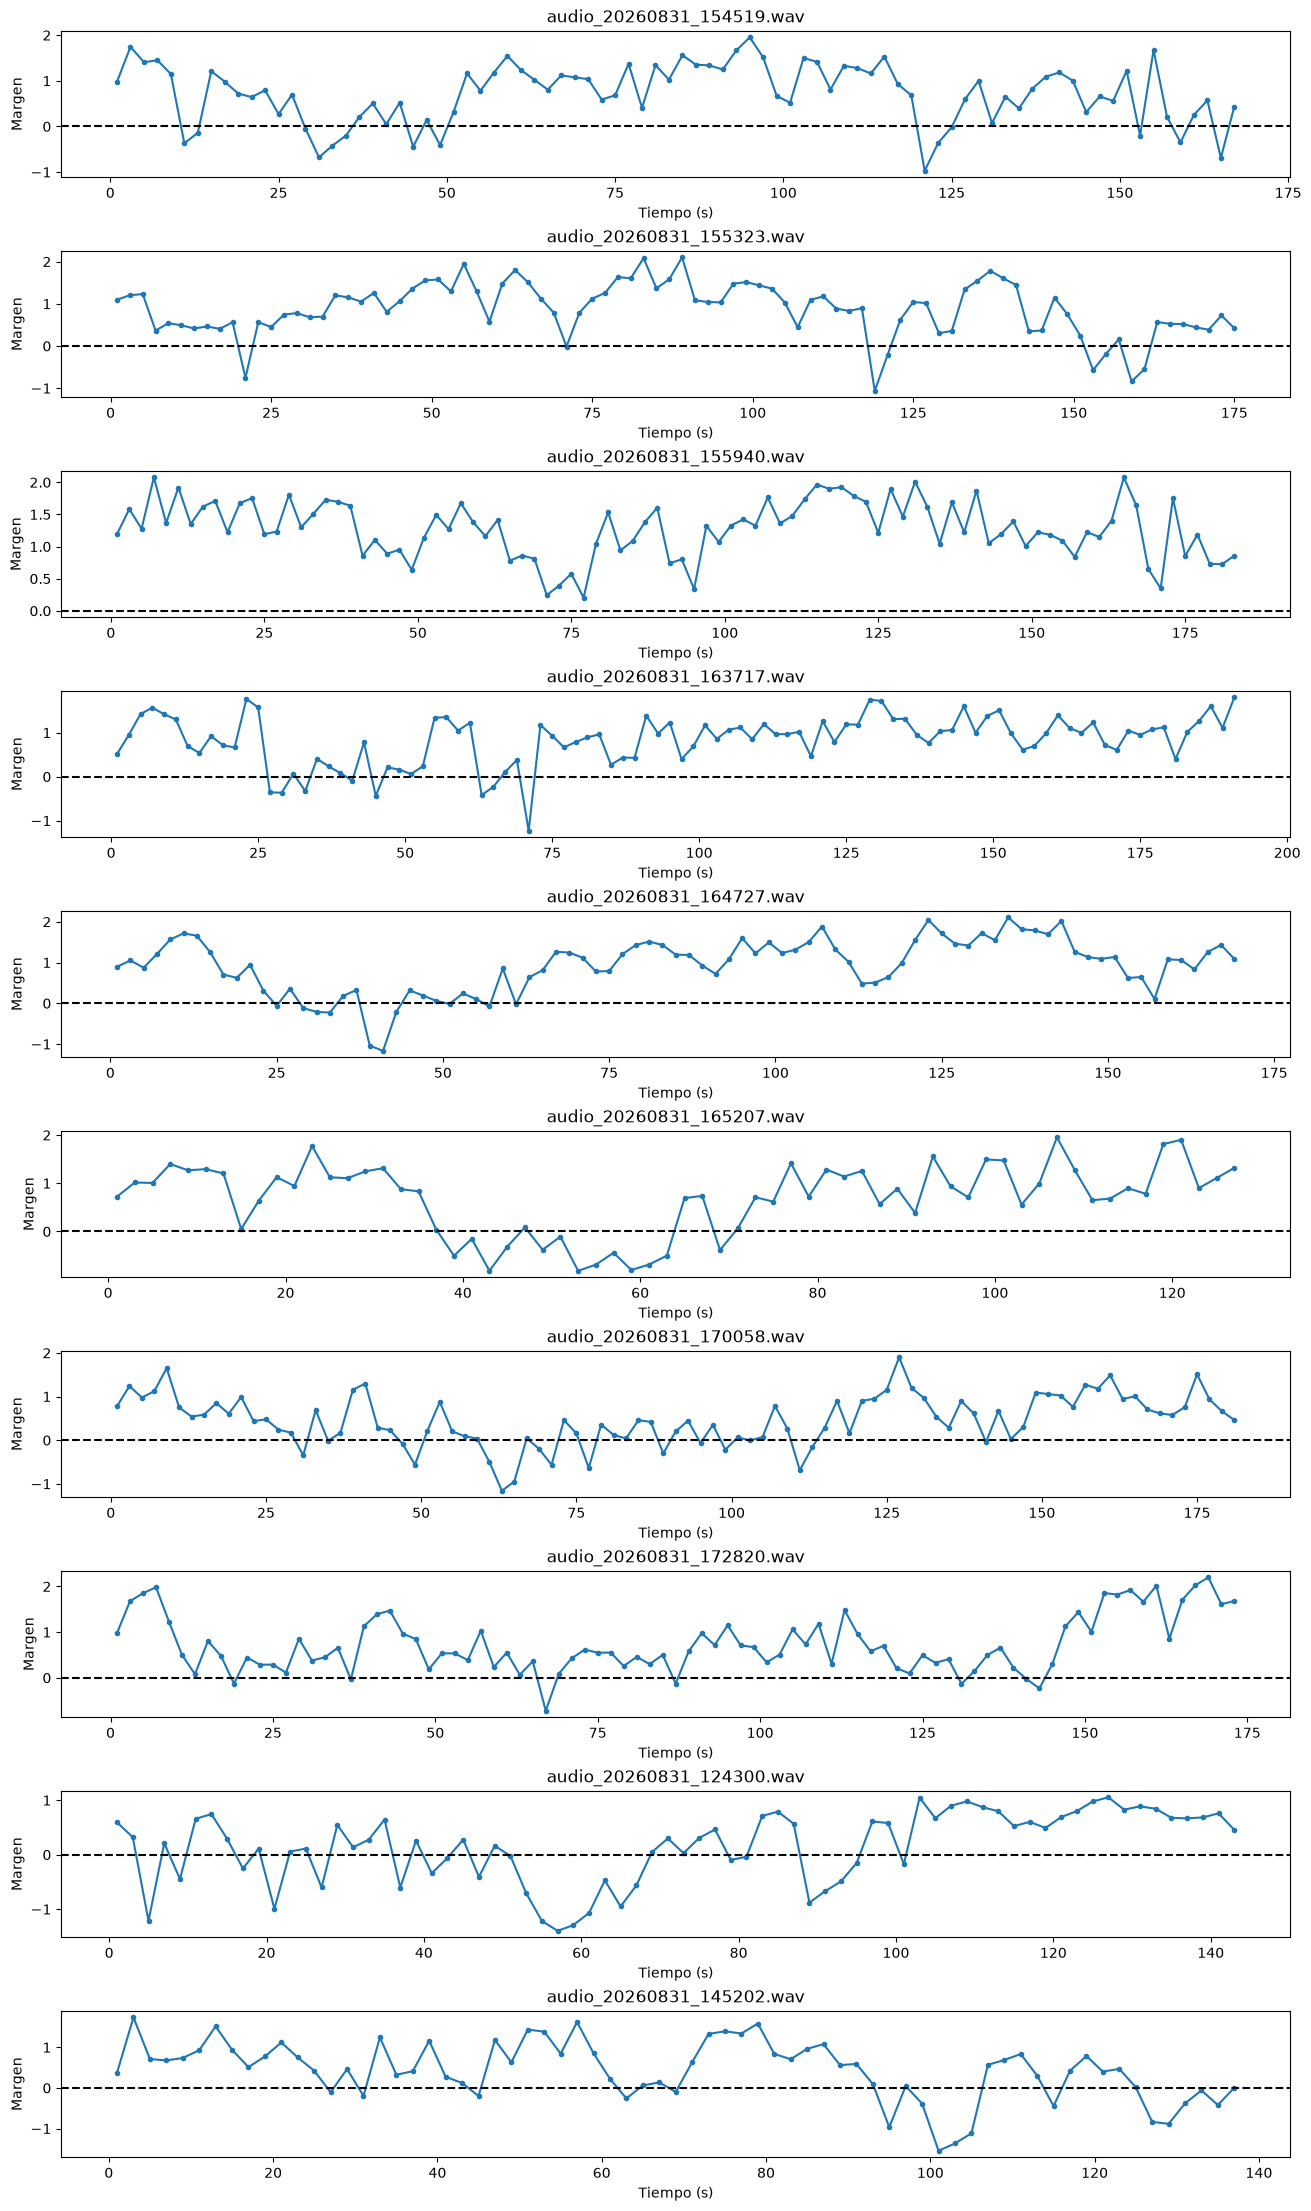

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for ax,(name,result) in zip(axes,oof.items()):
    ConfusionMatrixDisplay.from_predictions(y,result['pred'],display_labels=['Sin dron','Dron'],ax=ax,colorbar=False)
    ax.set_title(name + '\n[[VN, FP], [FN, VP]]'); ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
plt.show()
by_file=[]
for file in dict.fromkeys(r['file'] for r in rows):
    idx=np.array([i for i,r in enumerate(rows) if r['file']==file])
    pred=oof['MFCC_SVM']['pred'][idx]
    result=dict(file=file,fold=int(fold_id[idx[0]]),n=len(idx),
        positive_prediction_fraction=float(pred.mean()),label_positive_fraction=float(y[idx].mean()),
        **{k:v for k,v in metrics(y[idx],pred,oof['MFCC_SVM']['scores'][idx]).items() if k!='n'})
    by_file.append(result);print(result)
fig,axes=plt.subplots(len(by_file),1,figsize=(13,2.2*len(by_file)),constrained_layout=True,squeeze=False)
for ax,result in zip(axes.ravel(),by_file):
    idx=np.array([i for i,r in enumerate(rows) if r['file']==result['file']])
    t=np.array([(rows[i]['start_s']+rows[i]['end_s'])/2 for i in idx])
    ax.plot(t,oof['MFCC_SVM']['scores'][idx],'.-',label='Margen SVM fuera de entrenamiento')
    ax.axhline(0,color='black',ls='--');ax.set(title=result['file'],xlabel='Tiempo (s)',ylabel='Margen')
plt.show()


## Diagnóstico del inicio frente al resto
Compara recall en ventanas positivas por tiempo dentro del archivo: 0–15 s, 15–60 s y 60 s en adelante. Una ventana que cruza el límite se excluye de esta tabla. No interpretamos tiempo como distancia medida. Las predicciones son las obtenidas fuera de entrenamiento.


In [ ]:
for start,end,title in [(0,15,'0–15 s'),(15,60,'15–60 s'),(60,float('inf'),'Desde 60 s')]:
    idx=np.array([i for i,r in enumerate(rows) if r['label']==1 and r['start_s']>=start and r['end_s']<=end],dtype=int)
    if len(idx):
        vp=int(np.sum(oof['MFCC_SVM']['pred'][idx]==1));fn=len(idx)-vp
        print(title, '| VP:',vp,'FN:',fn,'Recall:',round(vp/len(idx),4))
always_positive=np.ones_like(y)
print('Referencia siempre dron:',metrics(y,always_positive,np.zeros(len(y))))
print('Un F1 alto debe compararse con esta referencia cuando predominan los positivos.')


0–15 s | VP: 54 FN: 2 Recall: 0.9643
15–60 s | VP: 139 FN: 37 Recall: 0.7898
Desde 60 s | VP: 409 FN: 38 Recall: 0.915
Referencia siempre dron: {'n': 828, 'VN': 0, 'FP': 141, 'FN': 0, 'VP': 687, 'recall': np.float64(1.0), 'precision': 0.8297101449275363, 'f1': 0.906930693069307, 'balanced_accuracy': np.float64(0.5), 'specificity': np.float64(0.0), 'average_precision': 0.8297101449275363, 'roc_auc': 0.5}
Un F1 alto debe compararse con esta referencia cuando predominan los positivos.


## 6. Guardar resultados y entrenar el prototipo final
El modelo final aprende de todos los datos etiquetados. **Sus predicciones sobre estos mismos archivos no son una evaluación independiente.** El resultado de referencia sigue siendo el obtenido en la sección 4. No se elige el modelo automáticamente mirando la evaluación: guardamos el SVM propuesto.

El archivo joblib contiene solo el Pipeline; al cargarlo en otro notebook se necesita también la función `vector` y la configuración guardada. Carga únicamente archivos joblib de confianza.

In [ ]:
# Revisar hasta tres errores. Son desacuerdos con las etiquetas disponibles,
# revisar especialmente cuando el dron es débilmente audible.
errors=np.flatnonzero(oof['MFCC_SVM']['pred']!=y)
for i in errors[:3]:
    r=rows[i];x,sr,_=read_audio(Path(r['path']))
    print('REVISAR:',r['file'],r['start_s'],r['end_s'],'etiqueta:',int(y[i]),
          'predicción:',int(oof['MFCC_SVM']['pred'][i]),'fuente:',r['label_source'])
    display(Audio(x[round(r['start_s']*sr):round(r['end_s']*sr),CHANNEL],rate=sr,normalize=False))


REVISAR: audio_20260831_154519.wav 10.0 12.0 etiqueta: 1 predicción: 0 fuente: presencia_confirmada_por_usuario


REVISAR: audio_20260831_154519.wav 12.0 14.0 etiqueta: 1 predicción: 0 fuente: presencia_confirmada_por_usuario


REVISAR: audio_20260831_154519.wav 28.0 30.0 etiqueta: 1 predicción: 0 fuente: presencia_confirmada_por_usuario


In [ ]:
final_model=make_pipeline(StandardScaler(),SVC(C=1.,gamma='scale',kernel='rbf'))
final_model.fit(X,y,svc__sample_weight=weights(y,groups))
joblib.dump(final_model,OUT/'mfcc_svm.joblib')
config=dict(labels="carpetas completas confirmadas por usuario",channel=CHANNEL,window_s=WINDOW_S,hop_s=HOP_S,sample_rate=next(iter(rates)),
    group_overrides=GROUP_OVERRIDES,seed=SEED,
    features='Hann32ms-hop10ms-HTK64-DCT20-excludeC0-mean-std',
    numpy=np.__version__,sklearn=sklearn.__version__,python=platform.python_version(),
    warning='Presencia física indicada por usuario; audibilidad variable; solo dos grabaciones negativas.')
(OUT/'configuracion.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
prediction_rows=[dict(r,fold=int(fold_id[i]),prediction=int(oof['MFCC_SVM']['pred'][i]),
                     score=float(oof['MFCC_SVM']['scores'][i])) for i,r in enumerate(rows)]
for name,data in [('auditoria',audit),('predicciones_oof',prediction_rows),('metricas_particiones',fold_results),('metricas_archivos',by_file)]:
    with (OUT/f'{name}.csv').open('w',newline='',encoding='utf-8-sig') as f:
        w=csv.DictWriter(f,fieldnames=list(data[0]));w.writeheader();w.writerows(data)
print('Guardado:',OUT.resolve())


Guardado: C:\Users\alche\Documents\Codex\2026-09-15\vamos-a-montar-un-proyecto-de\outputs\resultados_presencia_completa


## 7. Clasificar un audio nuevo
Introduce una ruta en `NEW_AUDIO`. El código avisa si coincide por contenido con una grabación del estudio. Se mantiene el canal, duración, frecuencia y extractor del entrenamiento. No se rellena la cola incompleta. La salida es experimental y no está calibrada.

In [ ]:
NEW_AUDIO = None  # Ejemplo: Path(r'C:\ruta\nuevo_audio.wav')
def classify_file(path):
    x,sr,digest=read_audio(Path(path))
    assert sr==config['sample_rate'],'Frecuencia diferente: no cambiarla sin definir remuestreo compatible.'
    if digest in seen: print('ATENCIÓN: archivo usado en el estudio; estas predicciones finales no son validación.')
    signal=x[:,CHANNEL];size=round(WINDOW_S*sr);step=round(HOP_S*sr)
    output=[]
    for start in range(0,len(signal)-size+1,step):
        score=float(final_model.decision_function(vector(signal[start:start+size],sr)[None,:])[0])
        output.append(dict(start_s=start/sr,end_s=(start+size)/sr,score=score,prediction=int(score>=0)))
    return output
if NEW_AUDIO is not None:
    new_predictions=classify_file(NEW_AUDIO)
    assert new_predictions,'Audio demasiado corto'
    with (OUT/'prediccion_nuevo_audio.csv').open('w',newline='',encoding='utf-8-sig') as f:
        w=csv.DictWriter(f,fieldnames=list(new_predictions[0]));w.writeheader();w.writerows(new_predictions)
    print(new_predictions[:10])


## Qué concluir y qué no
1. Si MFCC supera al volumen de forma consistente entre archivos, hay evidencia preliminar de información adicional al nivel. No demuestra que sea exclusiva del dron.
2. Si los resultados cambian mucho entre las dos particiones, prioriza más grabaciones negativas de sesiones diferentes.
3. Escucha falsos positivos y falsos negativos; investiga causas de error y documenta cambios antes de repetir. Tras usarlos para ajustar, ya no son un test final independiente.
4. Para ajustar C, gamma o umbral, utiliza validación interna agrupada y reserva nuevas sesiones para la prueba externa. Con dos negativos, esa selección anidada es muy limitada.
5. No atribuyas cientos de observaciones independientes a cientos de ventanas: la unidad de independencia es la sesión/grabación.

Referencias de contexto: [Jeon et al., EUSIPCO 2017](https://www.eurasip.org/Proceedings/Eusipco/Eusipco2017/papers/1570337347.pdf), [Kong et al., PANNs](https://arxiv.org/abs/1912.10211). Este notebook implementa una referencia propia; no reproduce sus resultados.
